## 1. Importação das Bibliotecas

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 2. Carregamento dos Dados e Visualização da Série Temporal

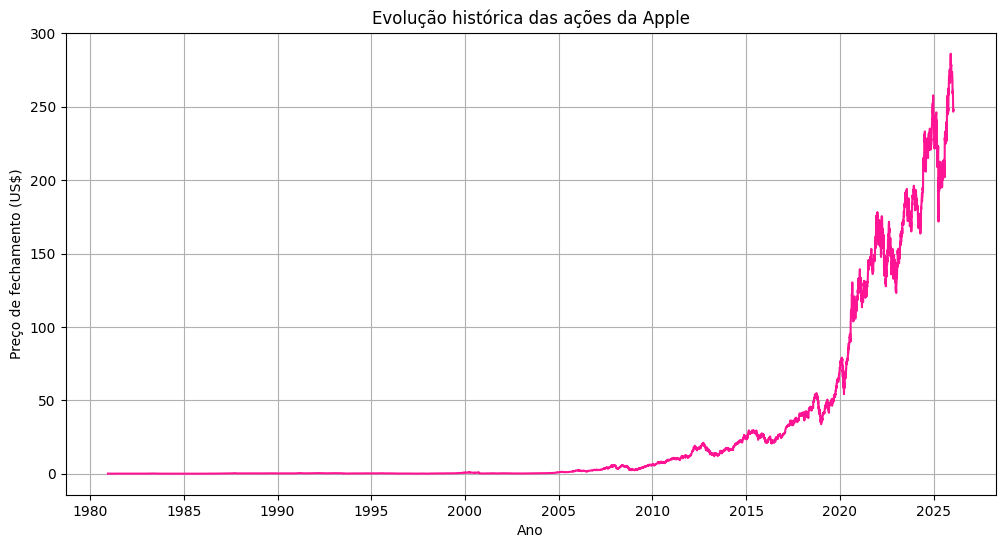

In [3]:
# Importando os dados
df = pd.read_csv('aapl_master_enriched.csv')

# Convertendo a coluna de datas
df['date'] = pd.to_datetime(df['date'])

# Organizando os registros cronologicamente
df = df.sort_values('date')

# Definindo a data como índice
df = df.set_index('date')

# Visualizando a série temporal
plt.figure(figsize=(12, 6))
plt.plot(df.index, df['close'], color='deeppink')

plt.title('Evolução histórica das ações da Apple')
plt.xlabel('Ano')
plt.ylabel('Preço de fechamento (US$)')
plt.grid(True)
plt.show()


## 3. Decomposição da Série Temporal: Tendência, Sazonalidade e Resíduos

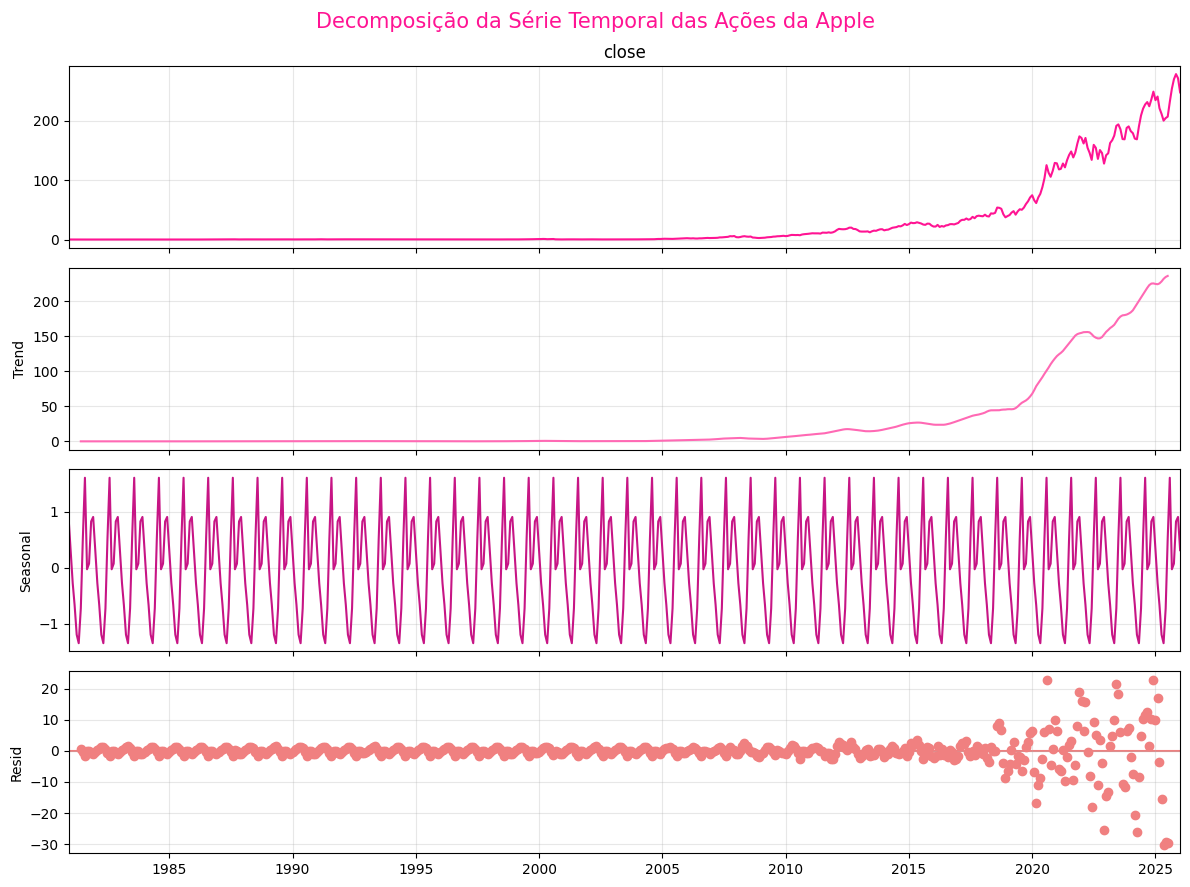

In [4]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Transformando os dados diários em mensais
serie_mensal = df['close'].resample('MS').last()

# Removendo possíveis valores ausentes
serie_mensal = serie_mensal.dropna()

# Realizando a decomposição da série temporal
decomposicao = seasonal_decompose(
    serie_mensal,
    model='additive',
    period=12
)

# Criando os gráficos
fig = decomposicao.plot()
fig.set_size_inches(12, 9)

# Alterando as linhas para tons de rosa
cores = ['deeppink', 'hotpink', 'mediumvioletred', 'lightcoral']

for ax, cor in zip(fig.axes, cores):
    for linha in ax.get_lines():
        linha.set_color(cor)
        linha.set_linewidth(1.5)
    ax.grid(True, alpha=0.3)

plt.suptitle(
    'Decomposição da Série Temporal das Ações da Apple',
    fontsize=15,
    color='deeppink'
)

plt.tight_layout()
plt.show()


## 4. Previsão da Série Temporal com Holt-Winters

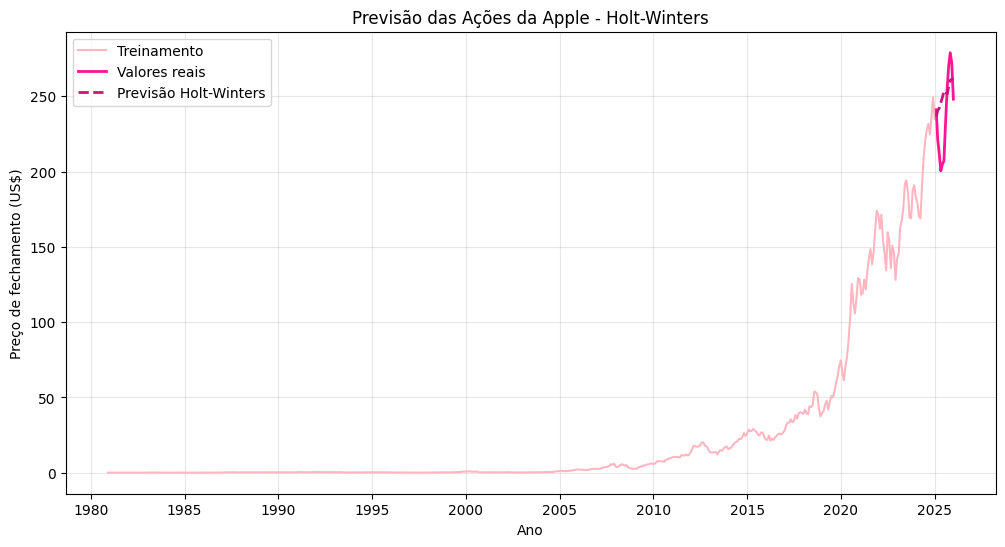

Resultados do Holt-Winters:
MAE: 22.6099
RMSE: 27.0063
MAPE: 10.26%


In [7]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1. Separando os dados de treinamento e teste
treino = serie_mensal.iloc[:-12]
teste = serie_mensal.iloc[-12:]

# 2. Criando e treinando o modelo Holt-Winters
modelo_hw = ExponentialSmoothing(
    treino,
    trend='add',
    seasonal='add',
    seasonal_periods=12,
    initialization_method='estimated'
)

ajuste_hw = modelo_hw.fit(optimized=True)

# 3. Prevendo os próximos 12 meses
previsao_hw = ajuste_hw.forecast(12)

# 4. Visualizando os resultados
plt.figure(figsize=(12, 6))

plt.plot(treino.index, treino,
         label='Treinamento', color='lightpink')

plt.plot(teste.index, teste,
         label='Valores reais', color='deeppink',
         linewidth=2)

plt.plot(previsao_hw.index, previsao_hw,
         label='Previsão Holt-Winters',
         color='mediumvioletred',
         linestyle='--', linewidth=2)

plt.title('Previsão das Ações da Apple - Holt-Winters')
plt.xlabel('Ano')
plt.ylabel('Preço de fechamento (US$)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 5. Calculando os erros
mae_hw = mean_absolute_error(teste, previsao_hw)
rmse_hw = np.sqrt(mean_squared_error(teste, previsao_hw))
mape_hw = np.mean(np.abs((teste - previsao_hw) / teste)) * 100

print("Resultados do Holt-Winters:")
print(f"MAE: {mae_hw:.4f}")
print(f"RMSE: {rmse_hw:.4f}")
print(f"MAPE: {mape_hw:.2f}%")
